In [2]:
import numpy as np
import matplotlib.pyplot as plt

import bisect

import essrs

In [3]:
def enclosed_probability(sigma: int, df: int) -> float:
    return 1 - np.exp(-(sigma**2) / df)

SIGMA_1 = enclosed_probability(1, 2)
SIGMA_2 = enclosed_probability(2, 2)
SIGMA_3 = enclosed_probability(3, 2)

print(SIGMA_1)
print(SIGMA_2)
print(SIGMA_3)

0.3934693402873666
0.8646647167633873
0.9888910034617577


In [4]:
ics = np.random.normal(loc=[0.5, 0.5], scale=0.1, size=(50,2))

fit = essrs.toy.toy_neals_funnel(
    max_n_steps=1000,        # max number of steps to run the sampler
    n_burn_in=2000,          # number of burn in steps to discard prior to main sampling stage
    initial_conditions=ics, # initial conditions
)

In [5]:
print(fit.shape)

x_fit = fit[:,:,0].ravel()
y_fit = fit[:,:,1].ravel()

(1000, 50, 2)


In [22]:
def neals_funnel(x: float, y: float) -> float:
    return 1. / (2 * np.pi) * np.exp(-0.5 * y**2) * np.exp(-y) * np.exp(-0.5 * (x / np.exp(y))**2)

In [27]:
xc = np.linspace(-20, 20, 1000)
yc = np.linspace(-4, 4, 1001)

dx = xc[1] - xc[0]
dy = yc[1] - yc[0]

gx, gy = np.meshgrid(xc, yc)
gz = neals_funnel(gx, gy)

gz /= np.sum(gz) * (dx * dy)

print(gz)


[[0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 ...
 [9.90381855e-07 9.90656324e-07 9.90930319e-07 ... 9.90930319e-07
  9.90656324e-07 9.90381855e-07]
 [9.52686747e-07 9.52946579e-07 9.53205960e-07 ... 9.53205960e-07
  9.52946579e-07 9.52686747e-07]
 [9.16351718e-07 9.16597672e-07 9.16843199e-07 ... 9.16843199e-07
  9.16597672e-07 9.16351718e-07]]


In [28]:
def estimate_enclosed_region(Z, target_sum):
    z = np.sort(Z.ravel(), descending=True)
    c = np.cumsum(z)
    i = bisect.bisect(c, target_sum)

    M = np.zeros_like(Z)
    M[z[i] < Z] = 1

    return M

In [29]:
M1 = estimate_enclosed_region(gz*dx*dy, SIGMA_1)
M2 = estimate_enclosed_region(gz*dx*dy, SIGMA_2)
M3 = estimate_enclosed_region(gz*dx*dy, SIGMA_3)

# generate the mask array highlighting the different regions in parameter space
M = M1 + M2 + M3

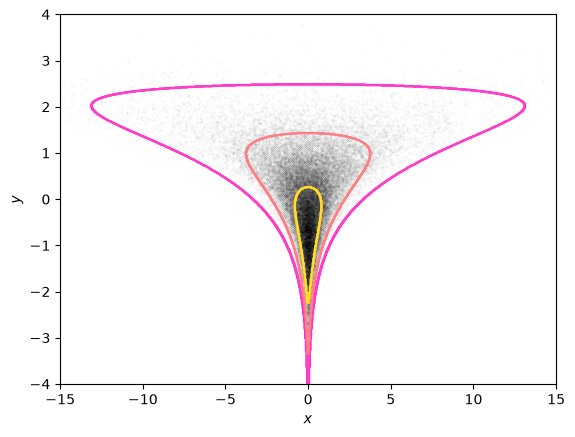

In [32]:
plt.figure()
plt.contour(gx, gy, M, cmap="spring")
plt.scatter(x_fit, y_fit, marker=".", s=0.1, color="k", alpha=0.1)
plt.xlabel(r"$x$")
plt.ylabel(r"$y$")
plt.xlim(-15, 15)
plt.show()

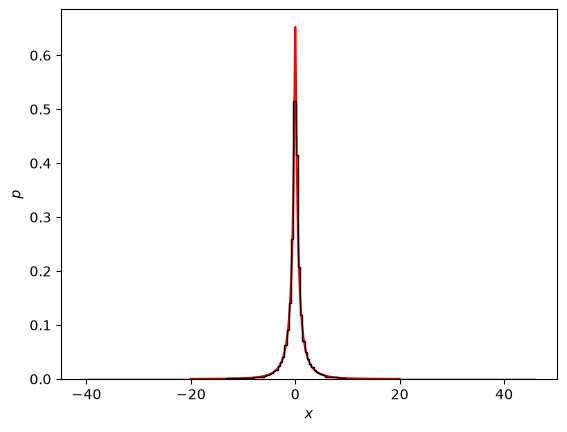

In [34]:
z_marg_y = np.sum(gz, axis=0)
z_marg_y /= np.sum(z_marg_y) * dx
plt.figure()
plt.plot(gx[0,:], z_marg_y, color="r")
plt.hist(x_fit, density=True, histtype="step", bins=200, color="k")
plt.xlabel(r"$x$")
plt.ylabel(r"$p$")
plt.show()

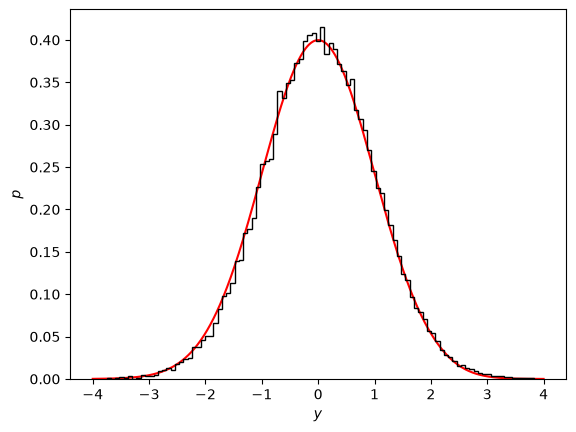

In [35]:
z_marg_x = np.sum(gz, axis=1)
z_marg_x /= np.sum(z_marg_x) * dy
plt.figure()
plt.plot(gy[:,0], z_marg_x, color="r")
plt.hist(y_fit, density=True, histtype="step", bins=100, color="k")
plt.xlabel(r"$y$")
plt.ylabel(r"$p$")
plt.show()